# Crack Classification — ResNet50

**Family:** CNN (classic baseline)
**Pretraining:** Loaded with ImageNet-pretrained weights, then fine-tuned on the crack dataset.
**Framework:** PyTorch + `timm`
**Dataset:** 40,000 images (20k crack / 20k no-crack) — 28k train / 8k val / 4k test

This notebook is self-contained — it trains and evaluates **only ResNet50**. Results (checkpoint, logs, metrics CSV) are saved with a `resnet50` prefix so you can run all 5 notebooks independently and combine results afterward.

**Class-index safety:** this notebook detects the crack/no-crack index mapping directly from your dataset folders at runtime (`class_to_idx`) instead of assuming an order, so precision/recall/F1/confusion-matrix/failure-analysis are all guaranteed correct regardless of how your folders happen to sort alphabetically.

## Expected dataset folder structure
```
DATA_DIR/
├── train/
│   ├── crack/
│   └── no_crack/
├── val/
│   ├── crack/
│   └── no_crack/
└── test/
    ├── crack/
    └── no_crack/
```


## 1. Setup — Install & Import

In [1]:
import sys
import torch
print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Python: C:\Users\Students\AppData\Local\Programs\Python\Python310\python.exe
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 5070


In [2]:
import sys
!{sys.executable} -m pip install -q timm scikit-learn seaborn grad-cam



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Students\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


In [3]:
import os
import time
import json
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import timm
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


C:\Users\Students\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
GPU: NVIDIA GeForce RTX 5070


## 2. Config — EDIT THIS CELL IF YOUR PATHS DIFFER

In [4]:
# ==== EDIT ME IF NEEDED ====
DATA_DIR = r"C:\Users\Students\Desktop\Crack classification(Indhu)\classification\dataset"
OUTPUT_DIR = r"C:\Users\Students\Desktop\Crack classification(Indhu)\Output"
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0   # keep at 0 on Windows to avoid multiprocessing/pickling errors
EPOCHS = 15       # bump up for real training; keep low first (e.g. 2) to sanity-check the pipeline
LR = 3e-4
NUM_CLASSES = 2

MODEL_KEY = "resnet50"
TIMM_NAME = "resnet50"
PRETRAINED = True
# ============================

print("Dataset exists:", os.path.exists(DATA_DIR))
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "checkpoints"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "logs"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "figures"), exist_ok=True)


Dataset exists: True


## 3. Dataset Analytics

In [5]:
def count_images(split_dir):
    counts = {}
    for c in ["crack", "no_crack"]:
        p = Path(split_dir) / c
        counts[c] = len(list(p.glob("*"))) if p.exists() else 0
    return counts

stats = {s: count_images(os.path.join(DATA_DIR, s)) for s in ["train", "val", "test"]}
stats_df = pd.DataFrame(stats).T
stats_df["total"] = stats_df.sum(axis=1)
print(stats_df)


       crack  no_crack  total
train  14000     14000  28000
val     4000      4000   8000
test    2000      2000   4000


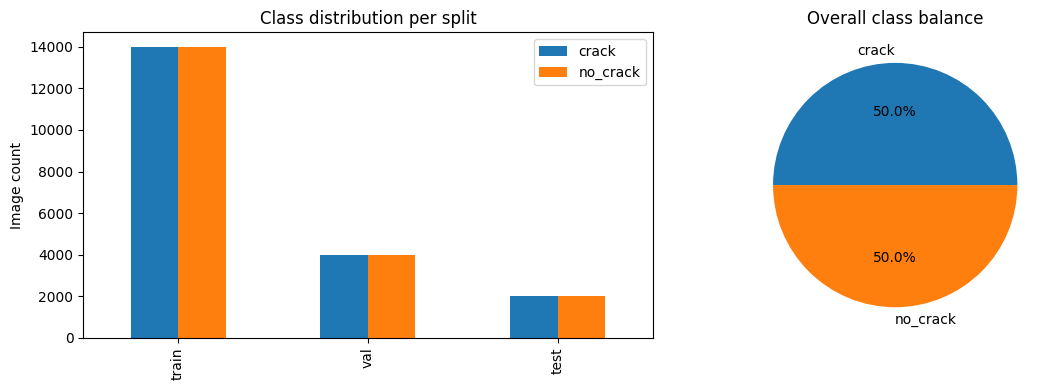

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
stats_df[["crack", "no_crack"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("Class distribution per split")
axes[0].set_ylabel("Image count")

totals = stats_df[["crack", "no_crack"]].sum()
axes[1].pie(totals, labels=totals.index, autopct="%1.1f%%")
axes[1].set_title("Overall class balance")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "figures", f"{MODEL_KEY}_dataset_analytics.png"), dpi=150)
plt.show()


## 4. Data Loaders

In [7]:
train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "train"), transform=train_tfms)
val_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "val"), transform=eval_tfms)
test_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "test"), transform=eval_tfms)

# ---- Determine crack/no-crack index mapping directly from the dataset ----
# ImageFolder assigns indices alphabetically by folder name, so "crack" and
# "no_crack" may NOT map to 0/1 the way you'd naively expect. Never hardcode this.
CRACK_IDX = train_ds.class_to_idx["crack"]
NO_CRACK_IDX = train_ds.class_to_idx["no_crack"]

print("Class-to-index mapping:", train_ds.class_to_idx)
print(f"CRACK_IDX = {CRACK_IDX}, NO_CRACK_IDX = {NO_CRACK_IDX}")
print("Train / Val / Test sizes:", len(train_ds), len(val_ds), len(test_ds))

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)


Class-to-index mapping: {'crack': 0, 'no_crack': 1}
CRACK_IDX = 0, NO_CRACK_IDX = 1
Train / Val / Test sizes: 28000 8000 4000


## 5. Model — ResNet50

In [8]:
def build_model():
    model = timm.create_model(TIMM_NAME, pretrained=PRETRAINED, num_classes=NUM_CLASSES)
    return model.to(DEVICE)

# Sanity check: confirm the model loads and does a forward pass
dummy = torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
model = build_model()
out = model(dummy)
n_params = sum(p.numel() for p in model.parameters())
print(f"{MODEL_KEY}: output shape={tuple(out.shape)}  params={n_params/1e6:.1f}M")


resnet50: output shape=(2, 2)  params=23.5M


## 6. Training & Evaluation Functions

In [9]:
def train_one_epoch(model, loader, criterion, optimizer, scaler=None, epoch=0, total_epochs=1):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    total_batches = len(loader)
    epoch_start = time.time()

    for batch_idx, (images, labels) in enumerate(loader, start=1):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        if scaler is not None:
            with torch.amp.autocast(device_type="cuda"):
                outputs = model(images)
                loss = criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (preds == labels).sum().item()

        if batch_idx == 1 or batch_idx % 25 == 0 or batch_idx == total_batches:
            elapsed = time.time() - epoch_start
            print(f"\rEpoch {epoch+1}/{total_epochs} | Batch {batch_idx}/{total_batches} | "
                  f"Loss: {running_loss/total:.4f} | Acc: {correct/total:.4f} | "
                  f"Time: {elapsed/60:.1f} min", end="", flush=True)
    print()
    return running_loss / total, correct / total


@torch.no_grad()
def evaluate_loss_acc(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    total_batches = len(loader)
    for batch_idx, (images, labels) in enumerate(loader, start=1):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if DEVICE.type == "cuda":
            with torch.amp.autocast(device_type="cuda"):
                outputs = model(images)
                loss = criterion(outputs, labels)
        else:
            outputs = model(images)
            loss = criterion(outputs, labels)
        running_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (preds == labels).sum().item()
        if batch_idx == 1 or batch_idx % 25 == 0 or batch_idx == total_batches:
            print(f"\rValidation | Batch {batch_idx}/{total_batches} | "
                  f"Loss: {running_loss/total:.4f} | Acc: {correct/total:.4f}", end="", flush=True)
    print()
    return running_loss / total, correct / total


@torch.no_grad()
def full_evaluate(model, loader):
    """Returns predictions, P(crack), true labels, and inference time.
    Uses CRACK_IDX (detected from the dataset) rather than assuming a column."""
    model.eval()
    all_preds, all_crack_probs, all_labels = [], [], []
    start = time.time()
    for imgs, labels in loader:
        imgs = imgs.to(DEVICE)
        outputs = model(imgs)
        crack_probs = torch.softmax(outputs, dim=1)[:, CRACK_IDX]
        preds = outputs.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_crack_probs.extend(crack_probs.cpu().numpy())
        all_labels.extend(labels.numpy())
    elapsed = time.time() - start
    avg_inference_time = elapsed / len(loader.dataset)
    return np.array(all_preds), np.array(all_crack_probs), np.array(all_labels), avg_inference_time


## 7. Train ResNet50

Includes: checkpoint + resume (safe to re-run this cell if interrupted — it picks up where it left off), per-epoch CSV logging, early stopping, and mixed precision for speed.


In [10]:
PATIENCE = 5

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda") if DEVICE.type == "cuda" else None

resume_path = os.path.join(OUTPUT_DIR, "checkpoints", f"{MODEL_KEY}_resume.pt")
ckpt_path = os.path.join(OUTPUT_DIR, "checkpoints", f"{MODEL_KEY}_best.pt")
csv_log_path = os.path.join(OUTPUT_DIR, "logs", f"{MODEL_KEY}_epoch_log.csv")
history_path = os.path.join(OUTPUT_DIR, "logs", f"{MODEL_KEY}_history.json")

if os.path.exists(resume_path):
    print("=" * 65)
    print("EXISTING CHECKPOINT FOUND — resuming training")
    print("=" * 65)
    ckpt = torch.load(resume_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt["model_state"])
    optimizer.load_state_dict(ckpt["optimizer_state"])
    scheduler.load_state_dict(ckpt["scheduler_state"])
    start_epoch = ckpt["epoch"] + 1
    history = ckpt["history"]
    best_val_acc = ckpt["best_val_acc"]
    best_state = ckpt["best_state"]
    epochs_no_improve = ckpt["epochs_no_improve"]
    if scaler is not None and "scaler_state" in ckpt:
        scaler.load_state_dict(ckpt["scaler_state"])
    print(f"Resuming from epoch {start_epoch+1}. Best val acc so far: {best_val_acc:.4f}")
else:
    print("=" * 65)
    print("STARTING NEW TRAINING")
    print("=" * 65)
    start_epoch = 0
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc = 0.0
    best_state = None
    epochs_no_improve = 0
    pd.DataFrame(columns=["epoch", "train_loss", "train_acc", "val_loss", "val_acc"]).to_csv(csv_log_path, index=False)

start_time = time.time()
stopped_early = False

for epoch in range(start_epoch, EPOCHS):
    print(f"\n{'='*65}\nEPOCH {epoch+1}/{EPOCHS}\n{'='*65}")
    print("\nTraining:")
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, scaler=scaler, epoch=epoch, total_epochs=EPOCHS)
    print("\nValidation:")
    val_loss, val_acc = evaluate_loss_acc(model, val_loader, criterion)
    scheduler.step()

    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"\nEpoch {epoch+1}/{EPOCHS} SUMMARY")
    print(f"Train Loss: {tr_loss:.4f}  Train Acc: {tr_acc*100:.2f}%")
    print(f"Val Loss:   {val_loss:.4f}  Val Acc:   {val_acc*100:.2f}%")

    pd.DataFrame([{
        "epoch": epoch + 1, "train_loss": tr_loss, "train_acc": tr_acc,
        "val_loss": val_loss, "val_acc": val_acc
    }]).to_csv(csv_log_path, mode="a", header=False, index=False)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
        print(f"NEW BEST MODEL! Val acc: {best_val_acc*100:.2f}%")
    else:
        epochs_no_improve += 1
        print(f"No improvement: {epochs_no_improve}/{PATIENCE}")

    checkpoint_data = {
        "epoch": epoch, "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(), "scheduler_state": scheduler.state_dict(),
        "history": history, "best_val_acc": best_val_acc,
        "best_state": best_state, "epochs_no_improve": epochs_no_improve,
    }
    if scaler is not None:
        checkpoint_data["scaler_state"] = scaler.state_dict()
    torch.save(checkpoint_data, resume_path)

    if epochs_no_improve >= PATIENCE:
        print(f"\nEARLY STOPPING — no improvement for {PATIENCE} consecutive epochs.")
        stopped_early = True
        break

training_time = time.time() - start_time
status = "Stopped early" if stopped_early else "Completed all epochs"
print(f"\n{'='*65}\nTRAINING FINISHED\n{'='*65}")
print(f"Status: {status}")
print(f"Best validation accuracy: {best_val_acc*100:.2f}%")
print(f"Training time: {training_time/60:.2f} minutes")

torch.save(best_state, ckpt_path)
with open(history_path, "w") as f:
    json.dump(history, f, indent=2)
model.load_state_dict(best_state)
print(f"Best model saved to: {ckpt_path}")


STARTING NEW TRAINING

EPOCH 1/15

Training:
Epoch 1/15 | Batch 875/875 | Loss: 0.1357 | Acc: 0.9505 | Time: 2.4 min

Validation:
Validation | Batch 250/250 | Loss: 0.0891 | Acc: 0.9680

Epoch 1/15 SUMMARY
Train Loss: 0.1357  Train Acc: 95.05%
Val Loss:   0.0891  Val Acc:   96.80%
NEW BEST MODEL! Val acc: 96.80%

EPOCH 2/15

Training:
Epoch 2/15 | Batch 875/875 | Loss: 0.0792 | Acc: 0.9711 | Time: 2.1 min

Validation:
Validation | Batch 250/250 | Loss: 0.0647 | Acc: 0.9784

Epoch 2/15 SUMMARY
Train Loss: 0.0792  Train Acc: 97.11%
Val Loss:   0.0647  Val Acc:   97.84%
NEW BEST MODEL! Val acc: 97.84%

EPOCH 3/15

Training:
Epoch 3/15 | Batch 875/875 | Loss: 0.0687 | Acc: 0.9755 | Time: 2.4 min

Validation:
Validation | Batch 250/250 | Loss: 0.0664 | Acc: 0.9736

Epoch 3/15 SUMMARY
Train Loss: 0.0687  Train Acc: 97.55%
Val Loss:   0.0664  Val Acc:   97.36%
No improvement: 1/5

EPOCH 4/15

Training:
Epoch 4/15 | Batch 875/875 | Loss: 0.0605 | Acc: 0.9783 | Time: 2.2 min

Validation:
Valida

## 8. Training Curves

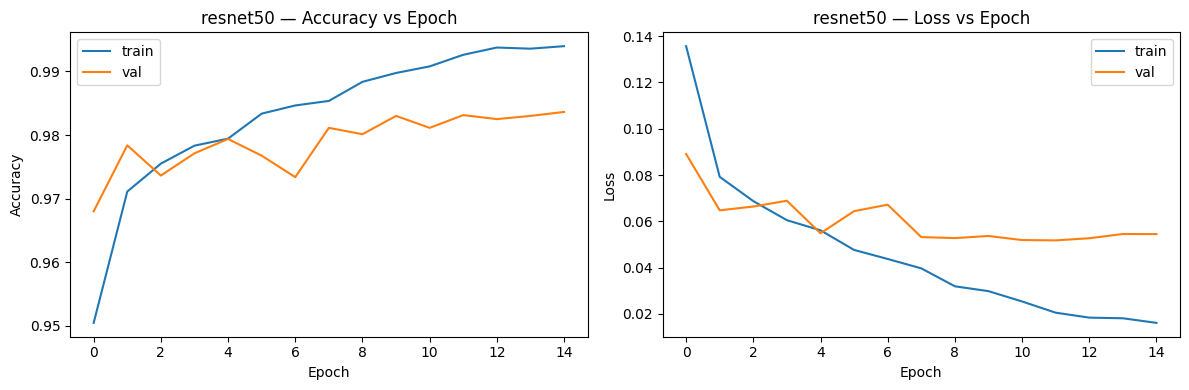

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_acc"], label="train")
axes[0].plot(history["val_acc"], label="val")
axes[0].set_title(f"{MODEL_KEY} — Accuracy vs Epoch")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].legend()

axes[1].plot(history["train_loss"], label="train")
axes[1].plot(history["val_loss"], label="val")
axes[1].set_title(f"{MODEL_KEY} — Loss vs Epoch")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "figures", f"{MODEL_KEY}_training_curves.png"), dpi=150)
plt.show()


## 9. Final Evaluation on Test Set

Builds a canonical binary encoding — **1 = crack, 0 = no_crack** — using `CRACK_IDX` detected in Section 4, so every metric below correctly treats "crack" as the positive class regardless of folder order.

In [12]:
preds, crack_probs, labels, avg_inf_time = full_evaluate(model, test_loader)

# Canonical binary encoding: 1 = crack, 0 = no_crack (independent of folder order)
labels_crack = (labels == CRACK_IDX).astype(int)
preds_crack = (preds == CRACK_IDX).astype(int)

acc = accuracy_score(labels_crack, preds_crack)
prec = precision_score(labels_crack, preds_crack, zero_division=0)
rec = recall_score(labels_crack, preds_crack, zero_division=0)
f1 = f1_score(labels_crack, preds_crack, zero_division=0)
auc = roc_auc_score(labels_crack, crack_probs)
cm = confusion_matrix(labels_crack, preds_crack)  # [0,0]=no_crack correct, [1,1]=crack correct
fpr, tpr, thresholds = roc_curve(labels_crack, crack_probs)
n_params = sum(p.numel() for p in model.parameters())

print("=" * 65)
print("CLASSIFICATION REPORT (0 = no_crack, 1 = crack)")
print("=" * 65)
print(classification_report(labels_crack, preds_crack, target_names=["no_crack", "crack"], zero_division=0))

result_row = {
    "Model": MODEL_KEY, "Accuracy": round(acc, 4),
    "Precision (crack)": round(prec, 4), "Recall (crack)": round(rec, 4),
    "F1-Score (crack)": round(f1, 4), "ROC-AUC": round(auc, 4),
    "Training Time (s)": round(training_time, 1),
    "Avg Inference Time (s/img)": round(avg_inf_time, 6),
    "Params (M)": round(n_params / 1e6, 2),
}
results_df = pd.DataFrame([result_row]).set_index("Model")
results_df.to_csv(os.path.join(OUTPUT_DIR, f"{MODEL_KEY}_final_metrics.csv"))
print(results_df)


CLASSIFICATION REPORT (0 = no_crack, 1 = crack)
              precision    recall  f1-score   support

    no_crack       0.98      0.99      0.99      2000
       crack       0.99      0.98      0.98      2000

    accuracy                           0.98      4000
   macro avg       0.99      0.98      0.98      4000
weighted avg       0.99      0.98      0.98      4000

          Accuracy  Precision (crack)  Recall (crack)  F1-Score (crack)  \
Model                                                                     
resnet50     0.985             0.9889           0.981            0.9849   

          ROC-AUC  Training Time (s)  Avg Inference Time (s/img)  Params (M)  
Model                                                                         
resnet50   0.9979             2247.4                    0.002853       23.51  


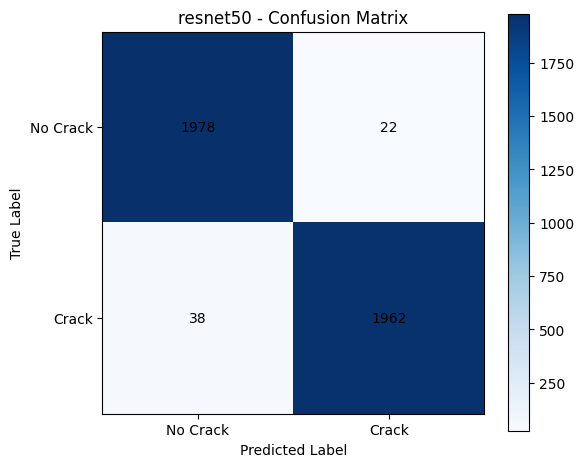

In [13]:
plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title(f"{MODEL_KEY} - Confusion Matrix")
plt.colorbar()
plt.xticks([0, 1], ["No Crack", "Crack"])
plt.yticks([0, 1], ["No Crack", "Crack"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "figures", f"{MODEL_KEY}_confusion_matrix.png"), dpi=150)
plt.show()


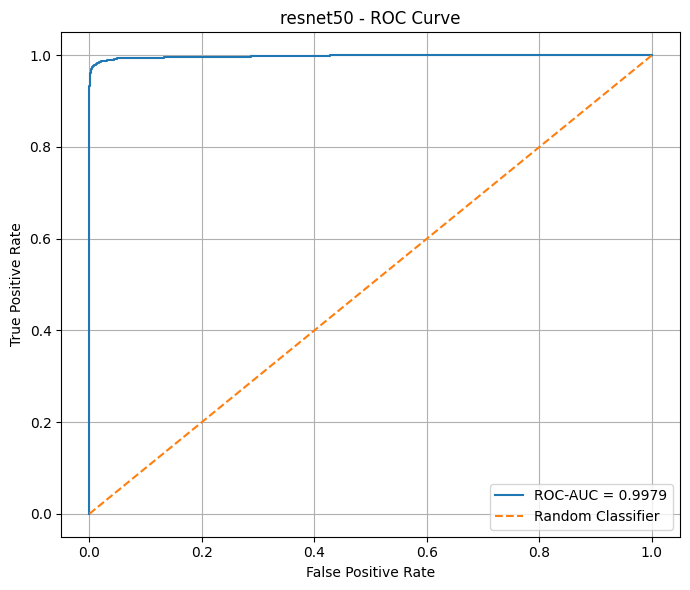

In [14]:
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"ROC-AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"{MODEL_KEY} - ROC Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "figures", f"{MODEL_KEY}_roc_curve.png"), dpi=150)
plt.show()

roc_df = pd.DataFrame({"False Positive Rate": fpr, "True Positive Rate": tpr, "Threshold": thresholds})
roc_df.to_csv(os.path.join(OUTPUT_DIR, f"{MODEL_KEY}_roc_curve.csv"), index=False)


## 10. Calibration Check — Is ResNet50 Honest About Its Confidence?

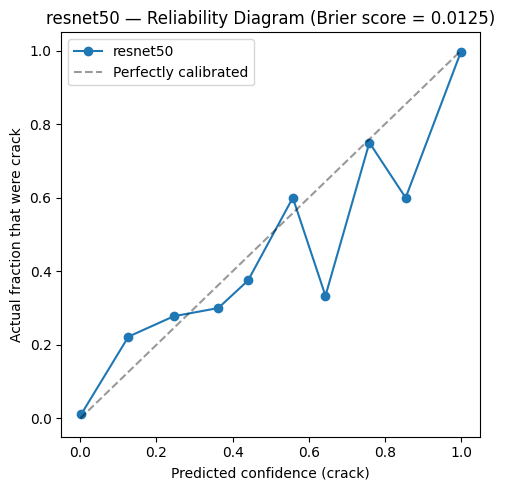

Brier score: 0.0125  (0 = perfect calibration, higher = worse)


In [15]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

prob_true, prob_pred = calibration_curve(labels_crack, crack_probs, n_bins=10, strategy="uniform")
brier = brier_score_loss(labels_crack, crack_probs)

plt.figure(figsize=(5, 5))
plt.plot(prob_pred, prob_true, marker="o", label=f"{MODEL_KEY}")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Perfectly calibrated")
plt.xlabel("Predicted confidence (crack)")
plt.ylabel("Actual fraction that were crack")
plt.title(f"{MODEL_KEY} — Reliability Diagram (Brier score = {brier:.4f})")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "figures", f"{MODEL_KEY}_calibration.png"), dpi=150)
plt.show()

print(f"Brier score: {brier:.4f}  (0 = perfect calibration, higher = worse)")
results_df["Brier Score"] = round(brier, 4)
results_df.to_csv(os.path.join(OUTPUT_DIR, f"{MODEL_KEY}_final_metrics.csv"))


## 11. Failure Case Analysis — What Did ResNet50 Get Wrong?

Uses the canonical `labels_crack` / `preds_crack` from Section 9 — "false positive" and "false negative" below are guaranteed correct regardless of dataset folder order.

In [16]:
test_paths = [p for p, _ in test_ds.samples]
misclassified_idx = np.where(preds_crack != labels_crack)[0]

print(f"{MODEL_KEY}: {len(misclassified_idx)} misclassified out of {len(labels_crack)} test images "
      f"({len(misclassified_idx)/len(labels_crack)*100:.1f}%)")

# False positive: predicted crack, actually no_crack
false_positives = [i for i in misclassified_idx if preds_crack[i] == 1 and labels_crack[i] == 0]
# False negative: predicted no_crack, actually crack (missed a real crack)
false_negatives = [i for i in misclassified_idx if preds_crack[i] == 0 and labels_crack[i] == 1]
print(f"False positives (said crack, wasn't): {len(false_positives)}")
print(f"False negatives (missed a real crack): {len(false_negatives)}")


resnet50: 60 misclassified out of 4000 test images (1.5%)
False positives (said crack, wasn't): 22
False negatives (missed a real crack): 38


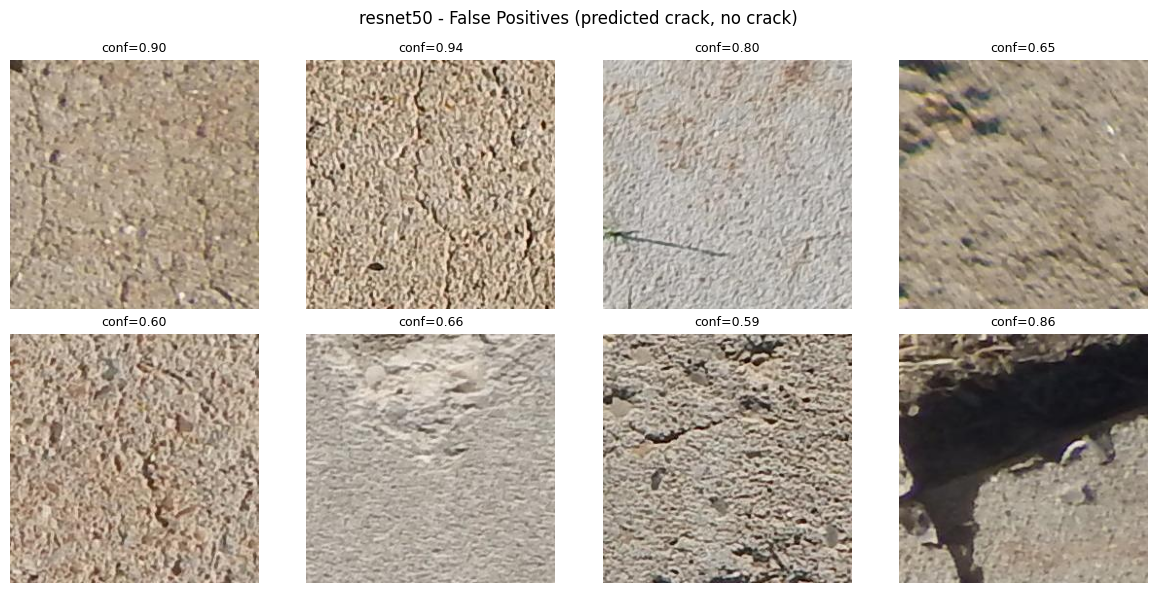

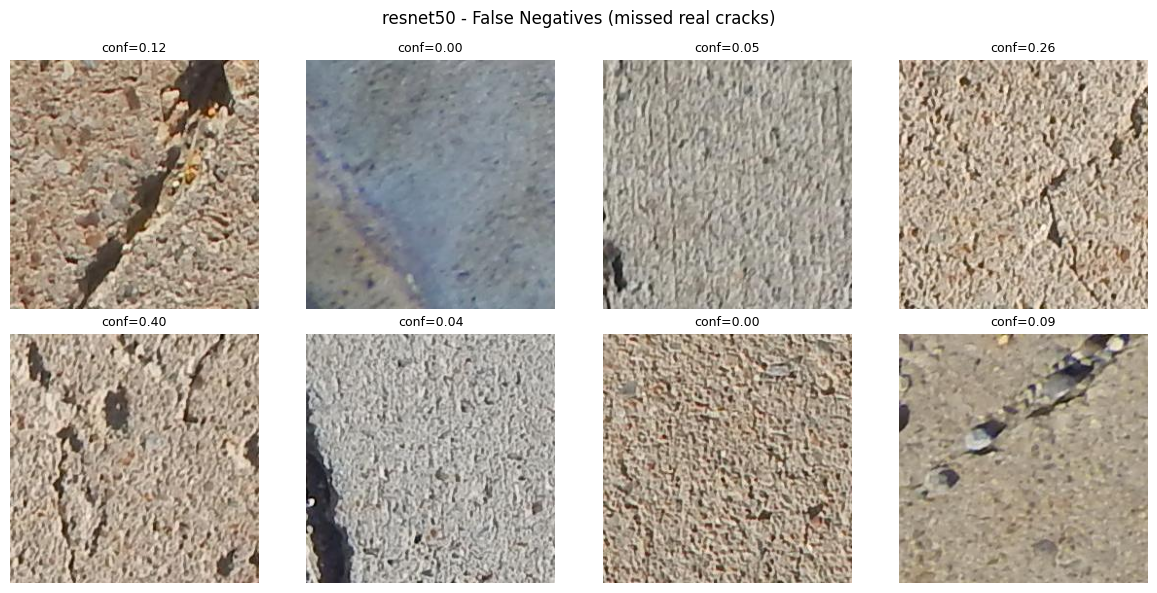

In [17]:
from PIL import Image

def show_failure_grid(indices, title, max_images=8):
    n = min(len(indices), max_images)
    if n == 0:
        print(f"No examples to show for: {title}")
        return
    cols = 4
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))
    axes = np.array(axes).reshape(-1)
    for ax_i in range(rows * cols):
        ax = axes[ax_i]
        ax.axis("off")
        if ax_i < n:
            idx = indices[ax_i]
            img = Image.open(test_paths[idx]).convert("RGB")
            ax.imshow(img)
            ax.set_title(f"conf={crack_probs[idx]:.2f}", fontsize=9)
    plt.suptitle(title)
    plt.tight_layout()
    fname = title.lower().replace(" ", "_").replace("(", "").replace(")", "").replace(",", "")
    plt.savefig(os.path.join(OUTPUT_DIR, "figures", f"{MODEL_KEY}_{fname}.png"), dpi=150)
    plt.show()

show_failure_grid(false_positives, f"{MODEL_KEY} - False Positives (predicted crack, no crack)")
show_failure_grid(false_negatives, f"{MODEL_KEY} - False Negatives (missed real cracks)")


**Write down what you notice** — this is the actual analysis, not the code above. Look at the grids: do false negatives tend to be thin/hairline cracks? Do false positives share something visually (shadows, stains, texture)? Are the wrong predictions high-confidence (concerning) or low-confidence (model was unsure)?


## 12. Grad-CAM (Explainability) — ResNet50

Dataset class mapping: {'crack': 0, 'no_crack': 1}
Actual: crack | Predicted: crack | Confidence: 100.00%


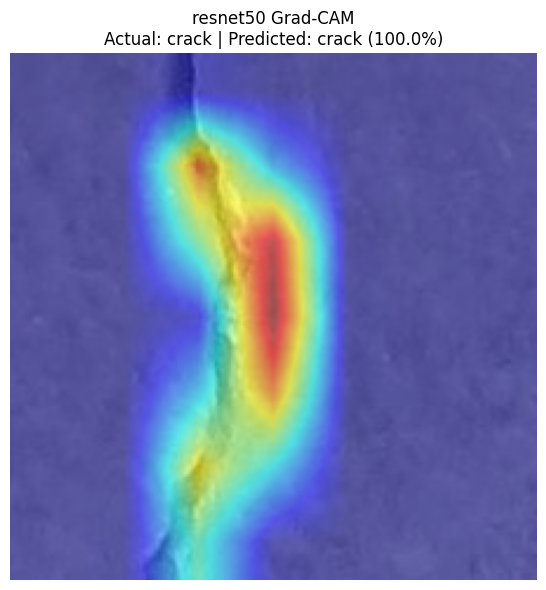

Actual: no_crack | Predicted: no_crack | Confidence: 100.00%


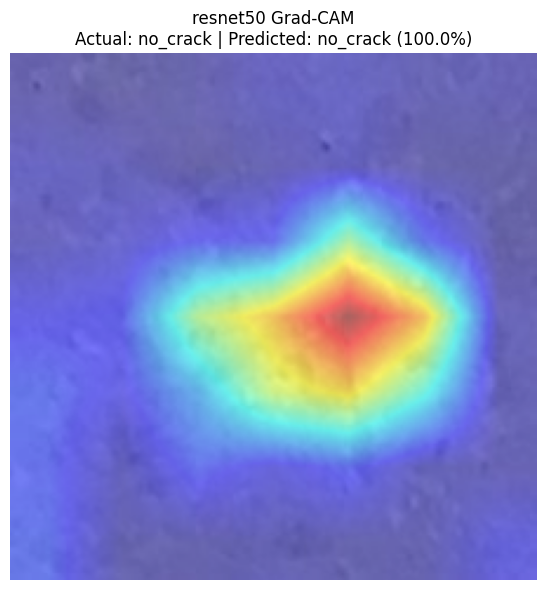

In [18]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print("Dataset class mapping:", test_ds.class_to_idx)

target_layers = [model.layer4[-1]]

def show_gradcam(image_path):
    model.eval()
    actual_class = os.path.basename(os.path.dirname(image_path))
    img = Image.open(image_path).convert("RGB")
    input_tensor = eval_tfms(img).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        output = model(input_tensor)
        probabilities = torch.softmax(output, dim=1)
        predicted_class = output.argmax(dim=1).item()

    class_names = test_ds.classes
    predicted_name = class_names[predicted_class]
    confidence = probabilities[0, predicted_class].item() * 100
    print(f"Actual: {actual_class} | Predicted: {predicted_name} | Confidence: {confidence:.2f}%")

    targets = [ClassifierOutputTarget(predicted_class)]
    cam = GradCAM(model=model, target_layers=target_layers)
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

    rgb_img = np.array(img.resize((IMG_SIZE, IMG_SIZE))).astype(np.float32) / 255.0
    visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    plt.figure(figsize=(6, 6))
    plt.imshow(visualization)
    plt.title(f"{MODEL_KEY} Grad-CAM\nActual: {actual_class} | Predicted: {predicted_name} ({confidence:.1f}%)")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

# Example usage — one crack image, one no_crack image:
crack_path = next(p for p, l in test_ds.samples if l == CRACK_IDX)
no_crack_path = next(p for p, l in test_ds.samples if l == NO_CRACK_IDX)
show_gradcam(crack_path)
show_gradcam(no_crack_path)


## 13. Summary

- Checkpoint: `OUTPUT_DIR\checkpoints\resnet50_best.pt`
- Training history: `OUTPUT_DIR\logs\resnet50_history.json`
- Final metrics (incl. Brier score): `OUTPUT_DIR\resnet50_final_metrics.csv`
- Figures: `OUTPUT_DIR\figures\resnet50_*.png`

If anything errors out, copy the exact error message and the cell it came from.
